In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model

In [2]:
df=pd.read_csv("LA_AQS_2023.csv")

In [3]:
df.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [4]:
df.columns

Index(['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC',
       'Latitude', 'Longitude', 'Datum', 'Parameter Name',
       'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year',
       'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type',
       'Nonreg Observation Count', 'Observation Count', 'Observation Percent',
       'Nonreg Arithmetic Mean', 'Arithmetic Mean',
       'Nonreg First Maximum Value', 'First Maximum Value',
       'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name',
       'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address',
       'MSA or CBSA Name', 'Data Source'],
      dtype='str')

In [5]:
df_NO2 = df[(df['Parameter Name']=='Nitrogen dioxide (NO2)') & (df['Duration Description']=='1 HOUR')]
df_NO2.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
19,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
29,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
41,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
44,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,20,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [6]:
df_O3 = df[(df['Parameter Name'] == 'Ozone') & (df['Duration Description'] == '1 HOUR')]
df_O3.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
20,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
64,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
204,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
228,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
271,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [7]:
df_O3["Arithmetic Mean"] = df_O3["Arithmetic Mean"] * 1000

In [8]:
df_O3["Arithmetic Mean"].head()

20     31.708
64     15.792
204    25.000
228    20.500
271    27.375
Name: Arithmetic Mean, dtype: float64

In [9]:
o3 = df_O3.rename(columns={"Arithmetic Mean": "o3_ppb"})[["Date (Local)", "o3_ppb"]]

In [10]:
o3.head()

,Date (Local),o3_ppb
20,2023-01-01,31.708
64,2023-01-02,15.792
204,2023-01-03,25.000
228,2023-01-04,20.500
271,2023-01-05,27.375


In [11]:
no2 = df_NO2.rename(columns={"Arithmetic Mean": "no2_ppb"})[["Date (Local)", "no2_ppb"]]

In [12]:
no2.head()

,Date (Local),no2_ppb
1,2023-01-01,4.816667
19,2023-01-01,4.550000
29,2023-01-01,4.550000
41,2023-01-01,4.816667
44,2023-01-02,14.720833


In [13]:
df_NO2[["Date (Local)", "POC", "Pollutant Standard", "Arithmetic Mean"]].head(10)

,Date (Local),POC,Pollutant Standard,Arithmetic Mean
1,2023-01-01,3,NO2 1-hour 2010,4.816667
19,2023-01-01,1,NO2 1-hour 2010,4.550000
29,2023-01-01,1,NO2 Annual 1971,4.550000
41,2023-01-01,3,NO2 Annual 1971,4.816667
44,2023-01-02,3,NO2 1-hour 2010,14.720833
62,2023-01-02,1,NO2 Annual 1971,15.416667
63,2023-01-02,1,NO2 1-hour 2010,15.416667
84,2023-01-02,3,NO2 Annual 1971,14.720833
138,2023-01-03,3,NO2 Annual 1971,11.716667
139,2023-01-03,3,NO2 1-hour 2010,11.716667


In [14]:
df_O3[["Date (Local)", "POC", "Pollutant Standard", "Arithmetic Mean"]].head(10)

,Date (Local),POC,Pollutant Standard,Arithmetic Mean
20,2023-01-01,1,Ozone 1-hour 1979,31.708
64,2023-01-02,1,Ozone 1-hour 1979,15.792
204,2023-01-03,1,Ozone 1-hour 1979,25.000
228,2023-01-04,1,Ozone 1-hour 1979,20.500
271,2023-01-05,1,Ozone 1-hour 1979,27.375
392,2023-01-06,1,Ozone 1-hour 1979,10.708
536,2023-01-07,1,Ozone 1-hour 1979,9.875
579,2023-01-08,1,Ozone 1-hour 1979,12.542
690,2023-01-09,1,Ozone 1-hour 1979,21.875
714,2023-01-10,1,Ozone 1-hour 1979,23.125


In [15]:
 (df_NO2["POC"] == 1) & (df_NO2["Pollutant Standard"] == "NO2 1-hour 2010")

1        False
19        True
29       False
41       False
44       False
         ...  
21264     True
21297    False
21298    False
21307    False
21308     True
Length: 1092, dtype: bool

In [16]:
df_no2_o3 = o3.merge(no2, how='inner', on='Date (Local)')

In [17]:
df_no2_o3.head()

,Date (Local),o3_ppb,no2_ppb
0,2023-01-01,31.708,4.816667
1,2023-01-01,31.708,4.550000
2,2023-01-01,31.708,4.550000
3,2023-01-01,31.708,4.816667
4,2023-01-02,15.792,14.720833


<Axes: xlabel='no2_ppb', ylabel='o3_ppb'>

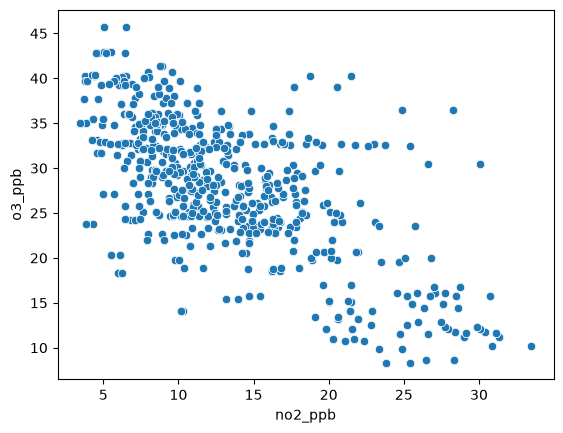

In [18]:
sns.scatterplot(data=df_no2_o3, x="no2_ppb", y="o3_ppb")

In [19]:
xVal = np.array(df_no2_o3["no2_ppb"]).reshape((-1, 1))
yVal = np.array(df_no2_o3["o3_ppb"])

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(xVal, yVal, test_size=0.20)

In [21]:
reg2 = linear_model.LinearRegression()
reg2.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.79]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,38.33
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[182.19]


In [22]:
print("Coefficients: \n", reg2.coef_)
print("Intercept: \n", reg2.intercept_)

Coefficients: 
 [-0.78619798]
Intercept: 
 38.327136106166876


In [23]:
df_test = pd.DataFrame({'x': X_test.ravel(), 'y': y_test.ravel()})
df_test['yPred'] = reg2.predict(X_test)

Text(0.5, 1.0, 'O3 vs NO2 Concentrations')

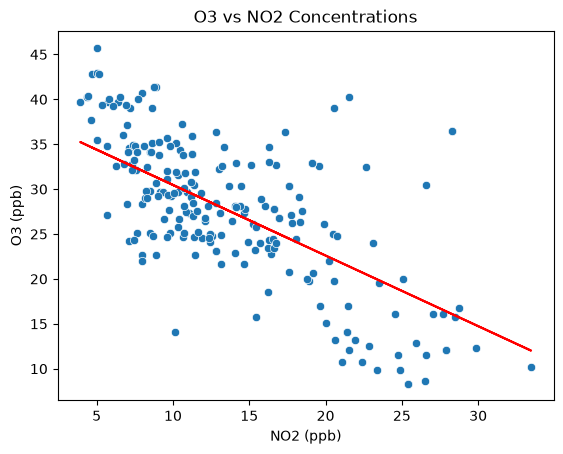

In [24]:
sns.scatterplot(data=df_test, x="x", y="y")
plt.plot(df_test["x"], df_test["yPred"], color="r")
plt.xlabel("NO2 (ppb)")
plt.ylabel("O3 (ppb)")
plt.title("O3 vs NO2 Concentrations")

In [25]:
from sklearn.metrics import mean_squared_error
mean_squared_error(df_test["y"], df_test["yPred"])

34.454446495154954

In [26]:
co2 = pd.read_csv("Manualoa_CO2.csv")

In [27]:
co2.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.70,314.43,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.71,-1,-9.99,-0.99
3,1958,6,1958.4548,317.24,315.14,-1,-9.99,-0.99
4,1958,7,1958.5370,315.86,315.18,-1,-9.99,-0.99


In [28]:
co2_train = co2[co2["year"] < 2000]
co2_train.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.70,314.43,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.71,-1,-9.99,-0.99
3,1958,6,1958.4548,317.24,315.14,-1,-9.99,-0.99
4,1958,7,1958.5370,315.86,315.18,-1,-9.99,-0.99


In [29]:
co2_test = co2[co2["year"] > 2000]
co2_test.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
514,2001,1,2001.0417,370.76,370.60,30,0.56,0.20
515,2001,2,2001.1250,371.69,370.95,26,0.61,0.23
516,2001,3,2001.2083,372.63,371.06,26,0.46,0.17
517,2001,4,2001.2917,373.55,370.99,29,0.56,0.20
518,2001,5,2001.3750,374.03,371.11,24,0.41,0.16


In [30]:
X_train = np.array(co2_train["decimal date"]).reshape((-1, 1))
y_train = np.array(co2_train["average"])

In [31]:
reg_co2 = linear_model.LinearRegression()
reg_co2.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.32]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2281
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[270.6]


In [32]:
X_test = np.array(co2_test["decimal date"]).reshape((-1, 1))
y_test = np.array(co2_test["average"])

In [33]:
yPred_co2 = reg_co2.predict(X_test)

In [34]:
df_co2_test = pd.DataFrame({
    "x": X_test.ravel(),
    "y": y_test.ravel()})
df_co2_test["yPred"] = yPred_co2

Text(0.5, 1.0, 'Mauna Loa CO2 vs Time')

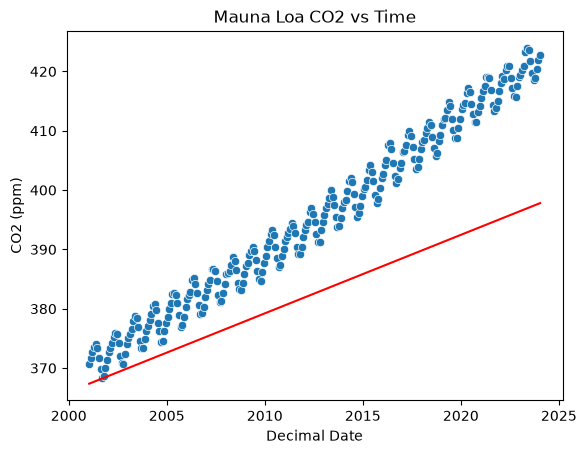

In [35]:
sns.scatterplot(data=df_co2_test, x="x", y="y")
plt.plot(df_co2_test["x"], df_co2_test["yPred"], color="r")
plt.xlabel("Decimal Date")
plt.ylabel("CO2 (ppm)")
plt.title("Mauna Loa CO2 vs Time")

In [36]:
mean_squared_error(df_co2_test["y"], df_co2_test["yPred"])

208.36826397223751

In [37]:
1. Fit a line* between O3 and NO2. Train on 80% of the data, test on 20%.
    
2. What is your test error? (Be sure to include units and the metric you used).
    The test error is 30.02ppb using mean squared error.
        
3. Do you think a linear model performs well? Why/why not? 
    Yes, the linear model performs well because it shows the overall negative relationship between NO2 and O3. Even though the points are pretty spread out, you can see the general relationship.

1. Fit a linear model* of CO2 vs. time (decimal date) using data before 2000.
    
2. Test your linear model on data after 2000. How well does it perform? 
    The model does not perform well on the data after 2000 because it underestimates the real CO2 concentrations.
        
3. Do you think a linear model performs well? Why/why not?
    No, the linear model doesn’t perform well because the concentration of CO2 increases much faster than the model predicts, so a straight line does not fit this well.



SyntaxError: invalid decimal literal (1819568210.py, line 4)